# 01 — Data Understanding

**Project:** Sales Demand Forecasting & Anomaly Detection
**Dataset:** Corporación Favorita store sales (Kaggle) — daily store-level sales for a large Ecuadorian grocery retailer.

## What this notebook does

Before we forecast anything, we must *understand* the raw data:

- how big it is and how it is structured,
- what types each column actually is,
- where values are missing,
- whether there are duplicates,
- what the "normal" vs "unusual" range of sales looks like,
- what time period we actually cover.

**Why do this before modeling?** Every later step (cleaning, feature engineering,
forecasting, anomaly detection) will be shaped by decisions we make here. A model is
only as trustworthy as the data it is trained on. Most "garbage in, garbage out"
problems are caught at this stage — not by fancy algorithms later.

> **Interview focus:** saying "in EDA I checked for missing values, duplicates and
> outliers" is not impressive. Saying *what you found* and *what decision it drove*
> is what demonstrates real Data Science thinking.

## Setup

We import the core libraries and set two display options so wide tables and larger
charts are easier to read. `pathlib.Path` lets us express file paths cleanly without
hard-coding backslashes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 100

# Raw data lives one folder up, under data/raw
DATA = Path("../data/raw")
assert (DATA / "train.csv").exists(), (
    "Run this notebook from the notebooks/ folder, and make sure data/raw contains the CSVs."
)

train = pd.read_csv(DATA / "train.csv", parse_dates=["Date"])
store = pd.read_csv(DATA / "store.csv")
print("Loaded.")


Loaded.


C:\Users\mande\AppData\Local\Temp\ipykernel_18540\3853696883.py:17: DtypeWarning: Columns (0: StateHoliday) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv(DATA / "train.csv", parse_dates=["Date"])


## 1. Shape and structure

`train` is one row per **store per day**; `store` is one row per store (metadata).
Understanding the grain (granularity) of the data is the single most important
structural question: every aggregation level we choose later must respect it.

In [2]:
print("train shape (rows, columns):", train.shape)
print("store shape (rows, columns):", store.shape)
print()
print("Training date range:", train["Date"].min().date(), "->", train["Date"].max().date())

train.head()

train shape (rows, columns): (1017209, 9)
store shape (rows, columns): (1115, 10)

Training date range: 2013-01-01 -> 2015-07-31


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


## 2. Column types

`dtypes` tells us whether each column is numeric, text, or a date — and therefore
which operations are legal on it. Note that `Date` was parsed as a proper datetime
(good, so we can sort and access `.dt.year` etc.). `StateHoliday` came in as text;
`Sales`/`Customers` must be treated as integers.

In [3]:
print(train.dtypes.to_string())
print("-" * 50)
train.info()

Store                     int64
DayOfWeek                 int64
Date             datetime64[us]
Sales                     int64
Customers                 int64
Open                      int64
Promo                     int64
StateHoliday             object
SchoolHoliday             int64
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   Date           1017209 non-null  datetime64[us]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  object        
 8   SchoolHoliday  1017209 no

## 3. Missing values

The question is not only *how many* values are missing, but *where* and *why*.
Missing values are expected in `store.csv` (some stores simply don't report
competition or promo fields) and surprising in `train.csv` (every store should have
a sales record for every day).

In [4]:
def missing_table(df):
    nulls = df.isna().sum()
    out = pd.DataFrame({"missing": nulls, "percent": (nulls / len(df) * 100).round(3)})
    return out[out["missing"] > 0]

print("Missing in train:")
print(missing_table(train) if not missing_table(train).empty else "  none")
print()
print("Missing in store:")
print(missing_table(store) if missing_table(store).empty else missing_table(store))


Missing in train:
  none

Missing in store:
                           missing  percent
CompetitionDistance              3    0.269
CompetitionOpenSinceMonth      354   31.749
CompetitionOpenSinceYear       354   31.749
Promo2SinceWeek                544   48.789
Promo2SinceYear                544   48.789
PromoInterval                  544   48.789


## 4. Duplicates

A "true" duplicate (every column identical) would usually be a data-entry bug.
A repeated `(Store, Date)` pair would be worse here, because this dataset's grain is
one row per store per day — two rows for the same store and day means the grain is
broken and our totals would be wrong.

In [5]:
print("Exact duplicate rows (all columns):", train.duplicated().sum())
print("Repeated (Store, Date) pairs:      ", train.duplicated(subset=["Store", "Date"]).sum())


Exact duplicate rows (all columns): 0


Repeated (Store, Date) pairs:       0


## 5. Outlier inspection

For time-series sales, an "outlier" is a value far from the typical range. But
outliers are **not automatically errors** — in retail, a huge sales day is very often
a real promo day or a state holiday. That makes them *information*, not noise.
Check: distribution stats, high/low quantiles, and how often stores are open/promoted.
(Formal anomaly detection comes later; here we just get a feel for the range.)

In [6]:
print(train[["Sales", "Customers"]].describe().round(2))
print()
print("Sales quantiles:")
print(train["Sales"].quantile([0.01, 0.25, 0.5, 0.75, 0.99]).round(1).to_string())


            Sales   Customers
count  1017209.00  1017209.00
mean      5773.82      633.15
std       3849.93      464.41
min          0.00        0.00
25%       3727.00      405.00
50%       5744.00      609.00
75%       7856.00      837.00
max      41551.00     7388.00

Sales quantiles:
0.01        0.0
0.25     3727.0
0.50     5744.0
0.75     7856.0
0.99    17160.0


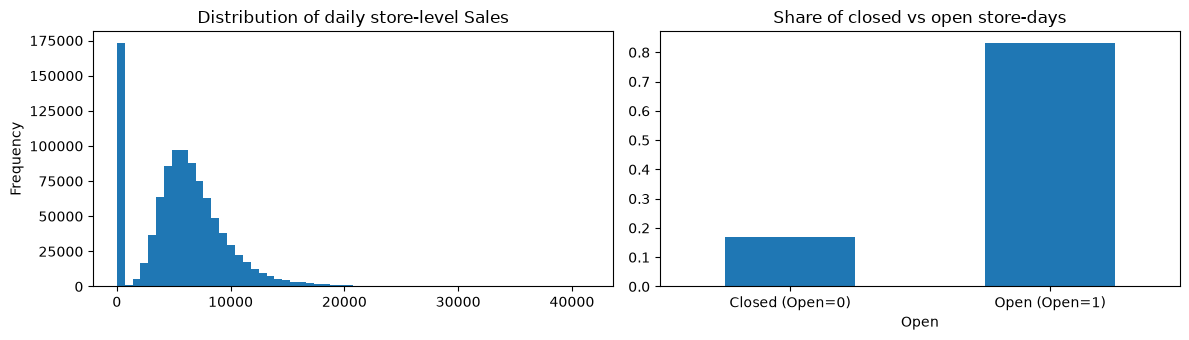

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
train["Sales"].plot(kind="hist", bins=60, ax=axes[0],
                    title="Distribution of daily store-level Sales")
train["Open"].value_counts(normalize=True).reindex([0, 1]).plot(
    kind="bar", ax=axes[1], title="Share of closed vs open store-days")
axes[1].set_xticklabels(["Closed (Open=0)", "Open (Open=1)"], rotation=0)
plt.tight_layout()
plt.show()

**Reading this:** the sales distribution is heavily right-skewed — many small
values and a long tail of large ones (plot 1). About a third of store-days have
Sales = 0 (plot 2), which happens when the store is *closed* (`Open = 0`). Both facts
matter hugely for modeling:

- Closed days are not "zero demand" — they are days with **no sales opportunity**.
- We must decide later whether to model `Open` as a feature or filter closed days.
- The long right tail is what our anomaly-detection step will later characterize.

### Promo and holiday context

`StateHoliday` looks like a simple categorical column, but the *details* matter:
notice that the raw column is **mixed-type** — `'0'` as a string and `0` as an
integer both mean "no public holiday". Pandas even printed a `DtypeWarning` at load
time. This is a real data-quality catch: Phase 2 must normalize it into one clean
categorical value before any grouping, or the two `0`s will be treated as different
groups (you can see them as two separate rows in the output below).


In [8]:
print(train["Promo"].value_counts(normalize=True).round(4).to_string())
print()
# Normalize StateHoliday to string so the two 'no holiday' codings ('0' vs 0) collapse
print("StateHoliday levels:", train["StateHoliday"].astype(str).unique())
print(train["StateHoliday"].astype(str).value_counts().to_string())
print()
print("SchoolHoliday:", train["SchoolHoliday"].value_counts(normalize=True).round(4).to_dict())


Promo
0    0.6185
1    0.3815

StateHoliday levels: <ArrowStringArray>
['0', 'a', 'b', 'c']
Length: 4, dtype: str
StateHoliday
0    986159
a     20260
b      6690
c      4100

SchoolHoliday: {0: 0.8214, 1: 0.1786}


## 6. Date range and coverage

We verify that the calendar is continuous and that every store has a row for every
day. If some `(Store, Date)` pairs are absent, our daily totals will silently dip —
which could look like an "anomalous drop" that is really just missing data.

In [9]:
n_distinct_dates = train["Date"].nunique()
n_stores = train["Store"].nunique()
cal_days = (train["Date"].max() - train["Date"].min()).days + 1
expected = n_stores * cal_days

print("Distinct dates :", n_distinct_dates, "(calendar days:", cal_days, ")")
print("Distinct stores:", n_stores)
print("Expected store-days:", expected)
print("Actual rows       :", len(train))
print("Missing store-days :", expected - len(train))


Distinct dates : 942 (calendar days: 942 )
Distinct stores: 1115
Expected store-days: 1050330
Actual rows       : 1017209
Missing store-days : 33121


**Note on the ~33K missing store-days:** this is expected if some stores opened
*after* 2013 or closed *before* 2015. Phase 2 must verify that these gaps are real
(new stores / permanent closures) and not accidental omissions — otherwise a simple
daily total could show a "drop" that is just data that was never recorded.

## 7. Unique values and top stores

The retailer has ~1,100 stores of four types. Knowing the top stores gives us a
natural *spotlight* unit for forecasting — we will not build 1,100 models; we will
aggregate, and zoom into representative stores.

In [10]:
print("Stores:", n_stores)
print("Store types in metadata:")
print(store["StoreType"].value_counts().to_string())
print()
print("Top 10 stores by total sales (USD):")
print(train.groupby("Store")["Sales"].sum().sort_values(ascending=False).head(10).to_string())


Stores: 1115
Store types in metadata:
StoreType
a    602
d    348
c    148
b     17

Top 10 stores by total sales (USD):
Store
262     19516842
817     17057867
562     16927322
1114    16202585
251     14896870
513     14252406
788     14082141
733     14067158
383     13489879
756     12911782


## 8. Descriptive statistics summary

`describe()` already showed us the core numbers. Two rules of thumb for *reading*
them:

- If **mean is well above median**, the series is right-skewed (a few big days pull
  the average up). Distribution check confirmed this for Sales.
- Baseline **variability** (std) is as important as level: it defines what "normal"
  means and hence how sensitive our anomaly detector will be.

Beyond that, the meaningful patterns of this data (weekly rhythm, holidays, trends)
are **not** visible in one table — that is exactly what EDA in Phase 2 is for.

In [11]:
train[["Sales", "Customers"]].agg(["mean", "median", "std", "min", "max"]).round(1).to_string()


'          Sales  Customers\nmean     5773.8      633.1\nmedian   5744.0      609.0\nstd      3849.9      464.4\nmin         0.0        0.0\nmax     41551.0     7388.0'

## Summary of findings (and the decisions they drive)

| Finding | Consequence for the project |
|---|---|
| Grain is one row per **store × day**, ~1.02M rows | Every aggregation must respect this; forecasting at store-type / network level is the sane scope |
| `Date` parses cleanly; 31 months, 2013-01-01 → 2015-07-31 | ~2.5 yearly cycles → expect *weekly* seasonality to be strong, *annual* weak |
| No missing values in `train`; some missing metadata in `store` | Cleaning focus is on `store.csv` metadata, not sales records |
| No duplicates, no repeated `(Store, Date)` | Grain is intact; totals are trustworthy |
| ~⅓ of store-days are closed with Sales = 0 | `Open` must enter the model as a real signal, not be treated as zero demand |
| Long right tail of big sales days | High-light "spikes" are often promo/holiday days — anomaly detection must compare against *expected* behavior, not call anything large an error |
| ~1,100 stores of 4 types | Forecast at network + store-type level; use top stores as case studies |

### What you should understand deeply before moving on

1. **Why zero sales ≠ zero demand** (closed stores). This is the kind of nuance
   interviewers probe with "what would you do if…".
2. **Data vs information**: a spike is not an error by default. Restating this
   directly separates a thoughtful project from a naive one.
3. **The grain of your data** and why every later decision depends on it.

Next: **Phase 2 — data cleaning & EDA**, where we act on these findings.